# Analyse des données de systèmes éducatifs — corrigé de référence

**Projet OpenClassrooms — parcours Data Engineer — livrable 1 (notebook)**

> **Contexte.** academy, start-up EdTech, propose des contenus de formation en ligne pour le lycée et l'université.
> Mark, son manager, prépare une expansion à l'international et pose deux questions :
> 1. Les données éducatives de la Banque mondiale (EdStats) peuvent-elles éclairer cette décision ?
> 2. Quels pays présentent un fort potentiel de clients, et comment ce potentiel évolue-t-il ?

| Partie | Ce qu'on y fait | Notion clé (fiche pédagogique) |
|---|---|---|
| 1. Exploration | comprendre les 5 fichiers, qualité, faux pays | `pedagogie/01_maille_et_qualite.ipynb` |
| 2. Réduction du périmètre | métier puis data : ~3 700 indicateurs → 15 | `pedagogie/02_filtrer_agreger.ipynb` |
| 3. Analyse et recommandation | redondance, distributions, score pays | `pedagogie/03_correlations.ipynb`, `pedagogie/04_distributions.ipynb` |

Les fonctions réutilisables (chargement, qualité, score) sont dans le package `src/edstats/`, testé avec `pytest`.

In [1]:
import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.analysis import (
    describe_and_plot,
    percentile_score,
    redundant_pairs,
    select_non_redundant,
    weight_sensitivity,
)
from edstats.cleaning import find_aggregates
from edstats.io import load_tables
from edstats.quality import FilterLog, fill_rate, missing_rate

viz.apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

### Paramètres de l'analyse

Toutes les hypothèses chiffrées sont regroupées ici : on les modifie à un seul endroit, jamais au milieu du code
(c'est le contraire du *hardcoding*). Chacune est justifiée plus bas, au moment où elle sert.

In [2]:
ANNEES_OBSERVEES = [str(a) for a in range(2010, 2015)]  # justifié en 2.2
SEUIL_REMPLISSAGE_INDICATEUR = 0.60  # part minimale de couples (pays, année) renseignés
MIN_ANNEES_PAR_PAYS = 3  # pas de médiane calculée sur 1 ou 2 années
SEUIL_CORRELATION = 0.70  # |ρ| au-delà duquel deux indicateurs sont jugés redondants
ANNEE_REFERENCE, ANNEE_PROJECTION = "2015", "2030"

---
## Partie 1 — Exploration des jeux de données

### 1.1 Chargement

`load_tables()` télécharge le zip si nécessaire, **vérifie son empreinte SHA-256** (on sait ainsi qu'on travaille
sur exactement le même fichier que celui du corrigé), puis lit les 5 CSV.

In [3]:
tables = load_tables()
for nom, df in tables.items():
    print(f"{nom:<15} {df.shape[0]:>9,} lignes × {df.shape[1]:>3} colonnes")

Country               241 lignes ×  32 colonnes
Series              3,665 lignes ×  21 colonnes
Country-Series        613 lignes ×   4 colonnes
FootNote          643,638 lignes ×   5 colonnes
Data              886,930 lignes ×  70 colonnes


In [4]:
tables["Data"].head(3)

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,...,2016,2017,2020,2025,2030,2035,2040,2045,2050,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, both sexes (%)",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, female (%)",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.2 Que représente une ligne ?

C'est **la** question à se poser avant tout calcul : elle conditionne chaque jointure et chaque agrégation.

In [5]:
cles = {
    "Country": ["Country Code"],
    "Series": ["Series Code"],
    "Country-Series": ["CountryCode", "SeriesCode"],
    "FootNote": ["CountryCode", "SeriesCode", "Year"],
    "Data": ["Country Code", "Indicator Code"],
}
signification = {
    "Country": "un pays (ou un agrégat de pays) et ses métadonnées",
    "Series": "un indicateur : définition, thème (Topic), source",
    "Country-Series": "une note méthodologique sur un indicateur pour un pays",
    "FootNote": "une note de bas de page pour un (pays, indicateur, année)",
    "Data": "les valeurs d'un indicateur pour un pays, une colonne par année",
}
pd.DataFrame(
    {
        "une ligne =": signification,
        "clé": {n: " + ".join(c) for n, c in cles.items()},
        "clé unique ?": {n: not tables[n].duplicated(c).any() for n, c in cles.items()},
    }
)

,une ligne =,clé,clé unique ?
Country,un pays (ou un agrégat de pays) et ses métadonnées,Country Code,True
Series,"un indicateur : définition, thème (Topic), source",Series Code,True
Country-Series,une note méthodologique sur un indicateur pour un pays,CountryCode + SeriesCode,True
FootNote,"une note de bas de page pour un (pays, indicateur, année)",CountryCode + SeriesCode + Year,True
Data,"les valeurs d'un indicateur pour un pays, une colonne par année",Country Code + Indicator Code,True


La colonne « clé unique ? » **prouve** l'interprétation : si deux lignes de `Data` partageaient le même
(pays, indicateur), notre lecture serait fausse.

### 1.3 Profil de chaque fichier

Une fonction appliquée dans une boucle `for` évite de copier-coller cinq fois le même code.

In [6]:
def profil(df: pd.DataFrame) -> dict:
    taux_nan = df.isna().mean()
    return {
        "lignes": len(df),
        "colonnes": df.shape[1],
        "doublons": int(df.duplicated().sum()),
        "colonnes numériques": len(df.select_dtypes("number").columns),
        "colonnes texte": len(df.select_dtypes(exclude="number").columns),
        "% de cellules vides": round(taux_nan.mean() * 100, 1),
        "colonnes 100 % vides": int((taux_nan == 1).sum()),
    }


pd.DataFrame({nom: profil(df) for nom, df in tables.items()}).T

,lignes,colonnes,doublons,colonnes numériques,colonnes texte,% de cellules vides,colonnes 100 % vides
Country,241.0,32.0,0.0,4.0,28.0,30.5,1.0
Series,3665.0,21.0,0.0,6.0,15.0,71.7,6.0
Country-Series,613.0,4.0,0.0,1.0,3.0,25.0,1.0
FootNote,643638.0,5.0,0.0,1.0,4.0,20.0,1.0
Data,886930.0,70.0,0.0,66.0,4.0,86.1,1.0


### 1.4 Doublons

Aucune ligne strictement identique (`duplicated()`), et aucune clé en double (vérifié en 1.2).
On applique tout de même `drop_duplicates()` : l'étape est gratuite et protège le notebook si les fichiers
sources changent un jour.

In [7]:
journal = FilterLog()
for nom in tables:
    avant = len(tables[nom])
    tables[nom] = tables[nom].drop_duplicates()
    journal.record(f"{nom} : suppression des doublons", avant, len(tables[nom]))
journal.to_frame()

,etape,lignes_avant,lignes_apres,lignes_supprimees
0,Country : suppression des doublons,241,241,0
1,Series : suppression des doublons,3665,3665,0
2,Country-Series : suppression des doublons,613,613,0
3,FootNote : suppression des doublons,643638,643638,0
4,Data : suppression des doublons,886930,886930,0


### 1.5 Valeurs manquantes

On commence par visualiser où elles se trouvent dans `Country` : chaque colonne est une bande, et chaque trait
blanc une valeur manquante.

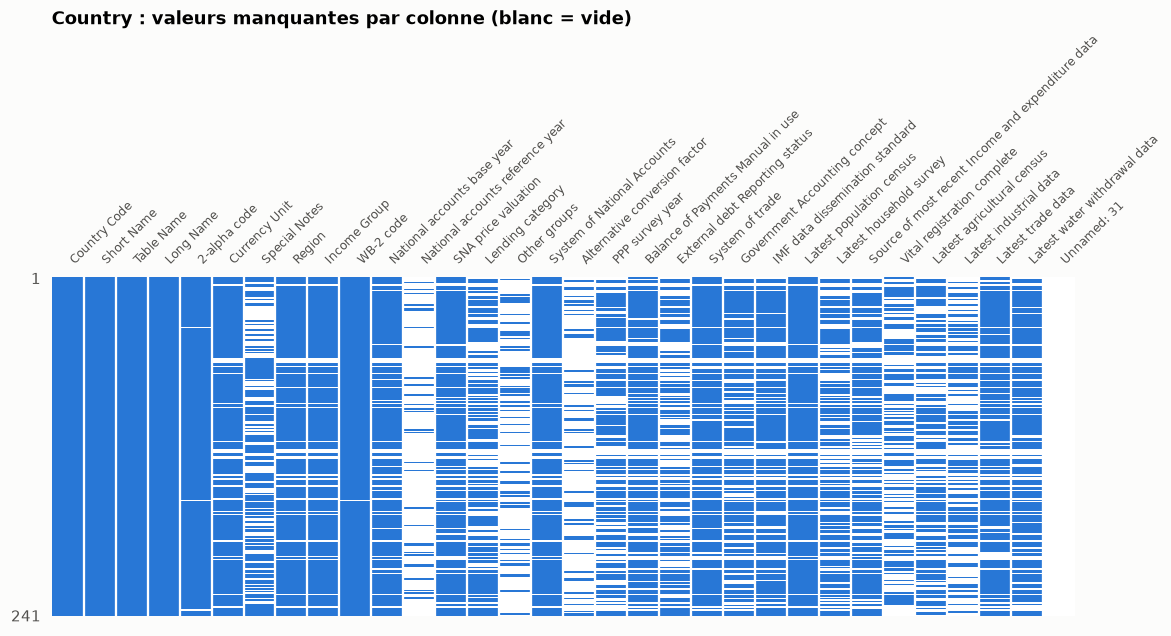

In [8]:
ax = msno.matrix(tables["Country"], figsize=(12, 4), fontsize=8, sparkline=False, color=(0.16, 0.47, 0.84))
ax.set_title("Country : valeurs manquantes par colonne (blanc = vide)", loc="left", fontsize=12)
plt.show()

In [9]:
missing_rate(tables["Data"]).to_frame("% manquant").T.round(1)

,Unnamed: 69,2017,2016,1973,1971,1972,1974,1979,1989,1976,1982,1977,1978,1983,1984,1988,1987,1981,1986,2050,...,2002,1990,2004,2003,2015,1995,2008,2007,2013,2006,2009,2011,2012,2000,2005,2010,Indicator Name,Indicator Code,Country Name,Country Code
% manquant,100.0,100.0,98.1,96.0,96.0,96.0,96.0,95.8,95.8,95.8,95.8,95.8,95.8,95.7,95.6,95.6,95.6,95.6,95.6,94.2,...,86.0,86.0,85.5,85.3,85.2,85.2,84.8,84.5,84.5,84.2,84.0,83.5,83.4,80.1,79.2,72.7,0.0,0.0,0.0,0.0


Constats :
- les colonnes `Unnamed: …` sont des artefacts d'export (une virgule en fin de ligne dans le CSV) : 100 % vides ;
- dans `Data`, **2017 est entièrement vide** et les années anciennes sont presque vides ;
- les colonnes 2020 → 2100 sont renseignées à environ 6 % : ce sont des **projections**, pas des observations (on y revient en 2.2).

On supprime les colonnes entièrement vides, qui sont inutilisables par construction.

In [10]:
for nom, df in tables.items():
    vides = df.columns[df.isna().all()]
    tables[nom] = df.drop(columns=vides)
    print(f"{nom:<15} colonnes supprimées : {list(vides)}")

Country         colonnes supprimées : ['Unnamed: 31']
Series          colonnes supprimées : ['Unit of measure', 'Notes from original source', 'Other web links', 'Related indicators', 'License Type', 'Unnamed: 20']
Country-Series  colonnes supprimées : ['Unnamed: 3']
FootNote        colonnes supprimées : ['Unnamed: 4']
Data            colonnes supprimées : ['Unnamed: 69']


### 1.6 Statistiques descriptives

**Colonnes catégorielles** : `value_counts()` sur les colonnes qui structurent l'analyse.

In [11]:
country, series = tables["Country"], tables["Series"]
display(country["Region"].value_counts(dropna=False).to_frame("pays par région"))
display(country["Income Group"].value_counts(dropna=False).to_frame("pays par groupe de revenu"))

,pays par région
Region,
Europe & Central Asia,57
Sub-Saharan Africa,48
Latin America & Caribbean,41
East Asia & Pacific,36
NaN,27
Middle East & North Africa,21
South Asia,8
North America,3


,pays par groupe de revenu
Income Group,
Upper middle income,55
Lower middle income,50
High income: nonOECD,44
Low income,34
High income: OECD,31
NaN,27


In [12]:
series["Topic"].value_counts().head(12).to_frame("nombre d'indicateurs")

,nombre d'indicateurs
Topic,
Learning Outcomes,1046
Attainment,733
Education Equality,426
Secondary,256
Primary,248
Population,213
Tertiary,158
Teachers,137
Expenditures,93


**Colonnes numériques** : `describe()` sur quelques années de `Data`.

In [13]:
tables["Data"][["2000", "2010", "2014", "2030"]].describe().round(1)

,2000,2010,2014,2030
count,1.766760e+05,2.424420e+05,1.137890e+05,51436.0
mean,9.423384e+09,1.189592e+10,2.678449e+10,631.6
std,4.442374e+11,6.218710e+11,1.023180e+12,16785.6
min,-6.759300e+04,-4.969050e+05,-8.900000e+01,-2.1
25%,5.700000e+00,1.300000e+00,1.610000e+01,0.1
50%,5.080000e+01,2.050000e+01,1.000000e+02,0.2
75%,3.343950e+04,3.121000e+03,1.636440e+05,7.1
max,6.327293e+13,9.134676e+13,1.108060e+14,1967258.2


`describe()` mélange ici ~3 700 indicateurs aux unités différentes (pourcentages, nombres d'habitants, dollars…).
La moyenne n'a donc **aucun sens** à ce stade : ce tableau sert seulement à constater l'énorme dispersion
(max ≫ Q3). Les statistiques descriptives ne deviendront interprétables qu'indicateur par indicateur (partie 3).

### 1.7 Premier nettoyage : les « faux pays »

`Country` contient des lignes qui ne sont pas des pays : « World », « Euro area », « High income »…
Garder ces agrégats fausserait toutes les comparaisons entre pays (le Monde serait premier sur la population !).

**Piste naïve** : les agrégats n'ont pas de `Region`.

In [14]:
sans_region = country.loc[country["Region"].isna(), ["Country Code", "Short Name", "2-alpha code"]]
print(len(sans_region), "lignes sans région")
sans_region

27 lignes sans région


,Country Code,Short Name,2-alpha code
5,ARB,Arab World,1A
57,EAP,East Asia & Pacific (developing only),4E
58,EAS,East Asia & Pacific (all income levels),Z4
59,ECA,Europe & Central Asia (developing only),7E
60,ECS,Europe & Central Asia (all income levels),Z7
63,EMU,Euro area,XC
68,EUU,European Union,EU
78,GIB,Gibraltar,GI
89,HIC,High income,XD
92,HPC,Heavily indebted poor countries (HIPC),XE


⚠️ Deux de ces lignes sont de **vrais territoires** : Gibraltar (`GI`) et Nauru (`NR`). Une règle sur la seule
colonne `Region` les supprimerait à tort.

**Règle retenue** : pas de région **et** un code alpha-2 réservé aux agrégats par la Banque mondiale
(code contenant un chiffre, commençant par X ou Z, ou `EU`/`OE`). La règle est codée et testée dans
`edstats.cleaning.find_aggregates`.

In [15]:
faux_pays = find_aggregates(country)
print(len(faux_pays), "faux pays :", faux_pays)

country = journal.apply(country, ~country["Country Code"].isin(faux_pays), "Country : faux pays")

25 faux pays : ['ARB', 'EAP', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'HIC', 'HPC', 'LAC', 'LCN', 'LDC', 'LIC', 'LMC', 'LMY', 'MEA', 'MIC', 'MNA', 'NAC', 'OED', 'SAS', 'SSA', 'SSF', 'UMC', 'WLD']


On retire maintenant les faux pays des autres tables, avec les **deux méthodes** demandées.

**Méthode 1 — liste + `~isin()`** : on exclut ce qui est dans la liste noire.

In [16]:
data_liste = tables["Data"][~tables["Data"]["Country Code"].isin(faux_pays)]
country_series_liste = tables["Country-Series"][~tables["Country-Series"]["CountryCode"].isin(faux_pays)]
footnote_liste = tables["FootNote"][~tables["FootNote"]["CountryCode"].isin(faux_pays)]

**Méthode 2 — inner join** : on ne garde que ce qui existe dans `Country` nettoyé (liste blanche).

In [17]:
codes_pays = country[["Country Code"]]
data_join = tables["Data"].merge(codes_pays, on="Country Code", how="inner")
country_series_join = tables["Country-Series"].merge(
    codes_pays, left_on="CountryCode", right_on="Country Code", how="inner"
).drop(columns="Country Code")
footnote_join = tables["FootNote"].merge(
    codes_pays, left_on="CountryCode", right_on="Country Code", how="inner"
).drop(columns="Country Code")

pd.DataFrame(
    {
        "liste ~isin()": [len(data_liste), len(country_series_liste), len(footnote_liste)],
        "inner join": [len(data_join), len(country_series_join), len(footnote_join)],
    },
    index=["Data", "Country-Series", "FootNote"],
)

,liste ~isin(),inner join
Data,795305,791640
Country-Series,613,613
FootNote,519100,518109


Les deux méthodes **ne donnent pas le même résultat** sur `Data`. Pourquoi ?

In [18]:
ecart = set(data_liste["Country Code"]) - set(data_join["Country Code"])
tables["Data"].loc[tables["Data"]["Country Code"].isin(ecart), ["Country Name", "Country Code"]].drop_duplicates()

,Country Name,Country Code
190580,British Virgin Islands,VGB


Les îles Vierges britanniques (`VGB`) figurent dans `Data` mais **pas** dans `Country`.
- La liste noire (`~isin`) les garde : elles ne sont pas un faux pays.
- La liste blanche (inner join) les retire : elles n'ont aucune métadonnée (région, revenu).

On retient l'**inner join** : la suite de l'analyse a besoin des métadonnées pays, et une liste blanche reste
sûre si un nouvel agrégat apparaît demain dans les données (une liste noire, elle, le laisserait passer).

In [19]:
journal.record("Data : faux pays (inner join)", len(tables["Data"]), len(data_join))
data, country_series, footnote = data_join, country_series_join, footnote_join
print(f"{data['Country Code'].nunique()} pays × {data['Indicator Code'].nunique()} indicateurs")

216 pays × 3665 indicateurs


---
## Partie 2 — Réduction du périmètre

Environ 3 700 indicateurs × 216 pays × 65 années : impossible d'analyser cela « à la main ».
On réduit en deux temps : d'abord avec le **métier** (ce qui a du sens pour academy), puis avec la **donnée**
(ce qui est assez renseigné pour être fiable).

### 2.1 Approche métier : choisir des familles d'indicateurs

La colonne `Topic` de `Series` classe chaque indicateur dans une famille. academy vend des **contenus en ligne**
à des **lycéens et étudiants** : on garde les familles qui décrivent la demande (démographie, scolarisation),
l'accès (internet) et la capacité à payer (économie).

In [20]:
familles_retenues = {
    "Population": "taille de la cible : effectifs par âge scolaire",
    "Health: Population: Structure": "structure par âge de la population",
    "Health: Population: Dynamics": "croissance démographique",
    "Secondary": "scolarisation au lycée",
    "Tertiary": "scolarisation à l'université",
    "Expenditures": "effort public d'éducation",
    "Infrastructure: Communications": "accès à internet (prérequis du e-learning)",
    "Economic Policy & Debt: Purchasing power parity": "pouvoir d'achat",
    "Economic Policy & Debt: National accounts: US$ at current prices: Aggregate indicators": "richesse",
    "Economic Policy & Debt: National accounts: US$ at constant 2010 prices: Aggregate indicators": "richesse",
    "Economic Policy & Debt: National accounts: Atlas GNI & GNI per capita": "revenu par habitant",
    "Social Protection & Labor: Unemployment": "chômage (besoin de se former)",
}
indicateurs_metier = series.loc[series["Topic"].isin(familles_retenues), "Series Code"]
print(f"{series['Topic'].nunique()} familles → {len(familles_retenues)} retenues")
print(f"{len(series)} indicateurs → {len(indicateurs_metier)} retenus")

37 familles → 12 retenues
3665 indicateurs → 751 retenus


Familles écartées, par exemple : *Learning Outcomes* (scores PISA, TIMSS… très lacunaires), les familles *SABER*
(évaluations qualitatives des politiques publiques), *Literacy* (alphabétisation des adultes, hors cible).

Les **projections** (*Attainment*, préfixe `PRJ`) sont mises de côté : elles serviront en 3.3 pour la question
« comment le potentiel évolue-t-il ? ».

On filtre maintenant **toutes** les tables sur ces indicateurs.

In [21]:
codes_projection = data.loc[data["Indicator Code"].str.startswith("PRJ.POP."), "Indicator Code"].unique()
projections = data[data["Indicator Code"].isin(codes_projection)]

data = journal.apply(data, data["Indicator Code"].isin(indicateurs_metier), "Data : familles métier")
series = journal.apply(series, series["Series Code"].isin(indicateurs_metier), "Series : familles métier")
country_series = journal.apply(
    country_series, country_series["SeriesCode"].isin(indicateurs_metier), "Country-Series : familles métier"
)
footnote = journal.apply(footnote, footnote["SeriesCode"].isin(indicateurs_metier), "FootNote : familles métier")

### 2.2 Quelles années garder ?

Les colonnes d'années vont de 1970 à 2100. Les années postérieures à 2017 (date de publication du jeu de
données) ne peuvent pas être des observations : ce sont des **projections** démographiques. On ne mélange jamais
observations et projections dans une même moyenne.

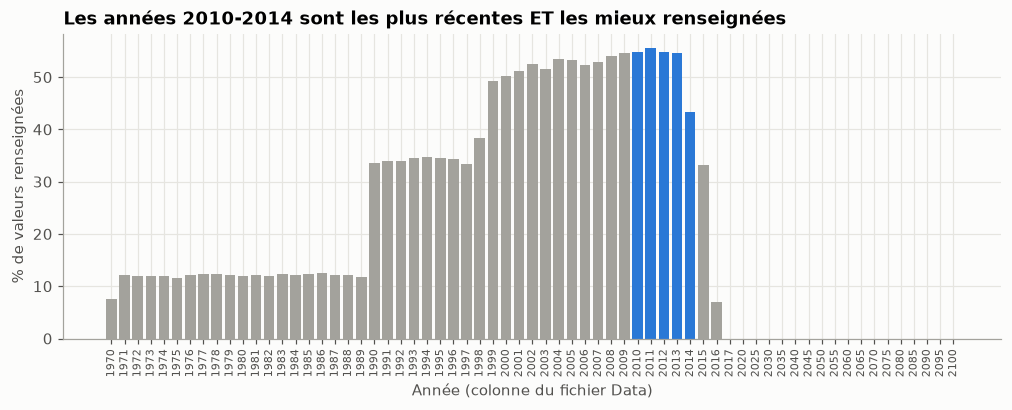

In [22]:
colonnes_annees = [c for c in data.columns if c.isdigit()]
remplissage_par_annee = data[colonnes_annees].notna().mean()

fig, ax = plt.subplots(figsize=(11, 3.6))
couleurs = [viz.BLUE if a in ANNEES_OBSERVEES else viz.MUTED for a in remplissage_par_annee.index]
ax.bar(remplissage_par_annee.index, remplissage_par_annee * 100, color=couleurs, width=0.8)
ax.set(
    title="Les années 2010-2014 sont les plus récentes ET les mieux renseignées",
    xlabel="Année (colonne du fichier Data)",
    ylabel="% de valeurs renseignées",
)
ax.tick_params(axis="x", rotation=90, labelsize=7)
viz.save(fig, "remplissage_par_annee")
plt.show()

Lecture :
- **pics tous les 5 ans** (1970, 1975… 2010) : certaines sources (Barro-Lee notamment) ne publient que des
  données quinquennales ;
- **2015, 2016, 2017** : le remplissage s'effondre, car les données n'étaient pas encore publiées au moment de
  l'export ;
- **2020 → 2100** : projections.

On garde **2010-2014** : le meilleur compromis entre actualité et remplissage. Les colonnes à supprimer sont
calculées avec `np.arange`, et non tapées une à une.

In [23]:
annees_a_supprimer = [str(a) for a in np.arange(1970, 2101) if str(a) not in ANNEES_OBSERVEES]
avant = data.shape[1]
data = data.drop(columns=data.columns[data.columns.isin(annees_a_supprimer)])
print(f"Data : {avant} → {data.shape[1]} colonnes")

Data : 69 → 9 colonnes


### 2.3 Approche data : garder les indicateurs les mieux renseignés

On passe `Data` du format **large** (une colonne par année) au format **long** (une ligne par pays × indicateur
× année) : les calculs par groupe deviennent alors un simple `groupby`.

In [24]:
data_long = data.melt(
    id_vars=["Country Code", "Indicator Code", "Indicator Name"],
    value_vars=ANNEES_OBSERVEES,
    var_name="annee",
    value_name="valeur",
)
print(f"{len(data_long):,} lignes (pays × indicateur × année)")

proportion_indicateurs_par_annee = fill_rate(data_long, by="annee", value="valeur")
proportion_annees_par_indicateur = fill_rate(data_long, by="Indicator Code", value="valeur")
proportion_indicateurs_par_annee.round(3).to_frame("part renseignée").T

784,080 lignes (pays × indicateur × année)


annee,2010,2011,2012,2013,2014
part renseignée,0.548,0.555,0.548,0.546,0.434


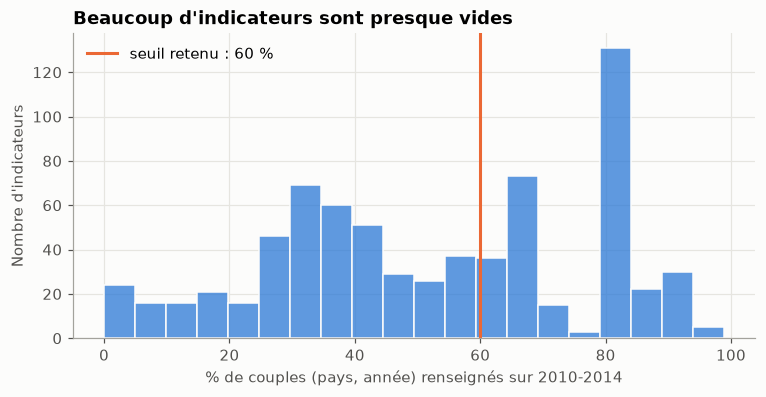

726 indicateurs → 314 au-dessus du seuil


In [25]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(proportion_annees_par_indicateur * 100, bins=20, color=viz.BLUE, edgecolor=viz.SURFACE, ax=ax)
ax.axvline(SEUIL_REMPLISSAGE_INDICATEUR * 100, color=viz.ORANGE, linewidth=2, label="seuil retenu : 60 %")
ax.set(
    title="Beaucoup d'indicateurs sont presque vides",
    xlabel="% de couples (pays, année) renseignés sur 2010-2014",
    ylabel="Nombre d'indicateurs",
)
ax.legend()
viz.save(fig, "remplissage_par_indicateur")
plt.show()

indicateurs_riches = proportion_annees_par_indicateur[
    proportion_annees_par_indicateur >= SEUIL_REMPLISSAGE_INDICATEUR
].index
print(f"{len(proportion_annees_par_indicateur)} indicateurs → {len(indicateurs_riches)} au-dessus du seuil")

Pour chaque indicateur et chaque année, on compte maintenant les **pays** renseignés, puis on trie : en tête
viennent les indicateurs utilisables partout dans le monde.

In [26]:
pays_par_indicateur_annee = (
    data_long[data_long["Indicator Code"].isin(indicateurs_riches)]
    .groupby(["Indicator Code", "Indicator Name", "annee"])["valeur"]
    .count()
    .unstack("annee")
)
pays_par_indicateur_annee["moyenne"] = pays_par_indicateur_annee.mean(axis=1).round(0)
pays_par_indicateur_annee.sort_values("moyenne", ascending=False).head(15)

,annee,2010,2011,2012,2013,2014,moyenne
Indicator Code,Indicator Name,,,,,,
SP.POP.TOTL,"Population, total",215,215,214,214,210,214.0
SP.POP.GROW,Population growth (annual %),215,214,214,214,210,213.0
SE.SEC.AGES,Official entrance age to lower secondary education (years),204,203,203,204,204,204.0
SE.SEC.DURS,Theoretical duration of secondary education (years),204,203,203,204,204,204.0
SE.SEC.DURS.UP,Theoretical duration of upper secondary education (years),204,203,203,204,204,204.0
IT.NET.USER.P2,Internet users (per 100 people),202,204,202,201,201,202.0
NY.GDP.PCAP.CD,GDP per capita (current US$),203,203,199,200,197,200.0
NY.GDP.MKTP.CD,GDP at market prices (current US$),203,203,199,200,197,200.0
NY.GDP.PCAP.KD,GDP per capita (constant 2005 US$),202,198,196,196,194,197.0


Parmi les indicateurs riches, on retient **15 indicateurs** couvrant les 4 dimensions du besoin. Plusieurs se
recouvrent probablement (population totale et population des 15-24 ans, par exemple) : c'est voulu, la
partie 3 tranchera **statistiquement** les redondances.

In [27]:
indicateurs_retenus = {
    # demande : combien de jeunes ?
    "SP.POP.1524.TO.UN": "Population 15-24 ans",
    "SP.SEC.UTOT.IN": "Population en âge du lycée",
    "SP.TER.TOTL.IN": "Population en âge universitaire",
    "SP.POP.TOTL": "Population totale",
    "SP.POP.GROW": "Croissance démographique (%)",
    "SP.POP.0014.TO.ZS": "Part des 0-14 ans (%)",
    # scolarisation : ces jeunes étudient-ils ?
    "SE.SEC.ENRR": "Taux brut de scolarisation secondaire (%)",
    "SE.TER.ENRR": "Taux brut de scolarisation supérieure (%)",
    "SE.SEC.ENRL": "Élèves du secondaire",
    "SE.TER.ENRL": "Étudiants du supérieur",
    # accès : peuvent-ils suivre un cours en ligne ?
    "IT.NET.USER.P2": "Utilisateurs d'internet (% population)",
    # solvabilité : peuvent-ils payer ?
    "NY.GDP.PCAP.PP.CD": "PIB par habitant (PPA, $ int.)",
    "NY.GNP.PCAP.CD": "RNB par habitant (Atlas, $ US)",
    "NY.GDP.MKTP.CD": "PIB (US$ courants)",
    "SL.UEM.TOTL.ZS": "Chômage (% population active)",
}
assert set(indicateurs_retenus) <= set(indicateurs_riches), "un indicateur retenu est sous le seuil"
print(len(indicateurs_retenus), "indicateurs retenus")

15 indicateurs retenus


> **Exception au seuil.** Le taux brut de scolarisation supérieure (`SE.TER.ENRR`), cœur de cible pour academy,
> est renseigné à 60,3 % sur 2010-2014, soit juste au-dessus du seuil. Sur 2010-2015, il serait tombé à 58 % :
> c'est l'une des raisons du choix 2010-2014. L'`assert` ci-dessus échouerait si une modification des paramètres le
> faisait repasser sous le seuil.

### 2.4 Consolider : une ligne par pays, une colonne par indicateur

`Data` est à la maille (pays, indicateur, année). Pour comparer des pays, on veut la maille **pays** : on résume
les 5 années par **la médiane**, qui est moins sensible qu'une moyenne à une année aberrante.
On exige au moins 3 années renseignées : une « médiane » d'une seule valeur n'est qu'une valeur isolée.

In [28]:
selection_long = data_long[data_long["Indicator Code"].isin(indicateurs_retenus)]

pays_indicateurs = selection_long.pivot_table(
    index="Country Code", columns="Indicator Code", values="valeur", aggfunc="median"
)
nb_annees = selection_long.pivot_table(
    index="Country Code", columns="Indicator Code", values="valeur", aggfunc="count"
)
pays_indicateurs = pays_indicateurs.where(nb_annees >= MIN_ANNEES_PAR_PAYS)
pays_indicateurs = pays_indicateurs[list(indicateurs_retenus)].rename(columns=indicateurs_retenus)
journal.record("Data → pivot pays × indicateurs", len(selection_long), len(pays_indicateurs))
print(pays_indicateurs.shape)
pays_indicateurs.head()

(216, 15)


Indicator Code,Population 15-24 ans,Population en âge du lycée,Population en âge universitaire,Population totale,Croissance démographique (%),Part des 0-14 ans (%),Taux brut de scolarisation secondaire (%),Taux brut de scolarisation supérieure (%),Élèves du secondaire,Étudiants du supérieur,Utilisateurs d'internet (% population),"PIB par habitant (PPA, $ int.)","RNB par habitant (Atlas, $ US)",PIB (US$ courants),Chômage (% population active)
Country Code,,,,,,,,,,,,,,,
ABW,13708.0,4553.0,6942.0,102577.0,0.512145,20.104897,97.015121,37.357700,7378.0,2330.0,74.000000,NaN,NaN,NaN,NaN
AFG,6569239.0,1977811.0,2724642.0,30696958.0,3.183201,46.739100,55.656158,NaN,2415884.0,NaN,5.454545,1873.153946,630.0,2.004633e+10,8.2
AGO,3972550.0,1493332.0,2129718.5,25096150.0,3.559496,47.306299,NaN,NaN,NaN,NaN,6.500000,6109.136612,3820.0,1.153984e+11,6.2
ALB,594101.0,170216.0,274639.0,2900401.0,-0.207047,20.470788,92.741470,58.565491,349269.0,160839.0,54.655959,10526.248328,4410.0,1.277628e+10,14.2
AND,NaN,NaN,NaN,82431.0,-1.588653,NaN,NaN,NaN,4208.0,498.0,86.434425,NaN,NaN,3.350736e+09,NaN


In [29]:
(pays_indicateurs.notna().mean() * 100).round(0).sort_values().to_frame("% de pays renseignés").T

Indicator Code,Taux brut de scolarisation supérieure (%),Étudiants du supérieur,Taux brut de scolarisation secondaire (%),Élèves du secondaire,Population en âge universitaire,Population 15-24 ans,Chômage (% population active),"PIB par habitant (PPA, $ int.)","RNB par habitant (Atlas, $ US)",Part des 0-14 ans (%),Population en âge du lycée,PIB (US$ courants),Utilisateurs d'internet (% population),Population totale,Croissance démographique (%)
% de pays renseignés,62.0,64.0,67.0,69.0,83.0,84.0,86.0,87.0,88.0,89.0,90.0,92.0,94.0,99.0,99.0


### Bilan du nettoyage

Le journal trace chaque filtre : c'est ce tableau qui alimente la slide « méthodologie » de la présentation.

In [30]:
journal.to_frame()

,etape,lignes_avant,lignes_apres,lignes_supprimees
0,Country : suppression des doublons,241,241,0
1,Series : suppression des doublons,3665,3665,0
2,Country-Series : suppression des doublons,613,613,0
3,FootNote : suppression des doublons,643638,643638,0
4,Data : suppression des doublons,886930,886930,0
5,Country : faux pays,241,216,25
6,Data : faux pays (inner join),886930,791640,95290
7,Data : familles métier,791640,156816,634824
8,Series : familles métier,3665,751,2914
9,Country-Series : familles métier,613,613,0


---
## Partie 3 — Analyse et recommandation

### 3.1 Indicateurs redondants : corrélations de Pearson et de Spearman

- **Pearson** mesure une relation **linéaire** et est très sensible aux valeurs extrêmes (Chine, Inde, États-Unis
  écrasent tout sur les effectifs).
- **Spearman** applique Pearson aux **rangs** : il mesure une relation **monotone** (« quand l'un monte, l'autre
  monte ») et résiste aux valeurs extrêmes.

Nos indicateurs sont très asymétriques (populations, PIB) : **Spearman est la référence**, et Pearson sert de
comparaison.

⚠️ `corr()` ignore, pour chaque paire, les pays où l'une des deux valeurs manque : chaque coefficient est donc
calculé sur un sous-ensemble de pays différent. On l'affiche pour savoir de quoi on parle.

Nombre de pays par paire : de 114 à 214


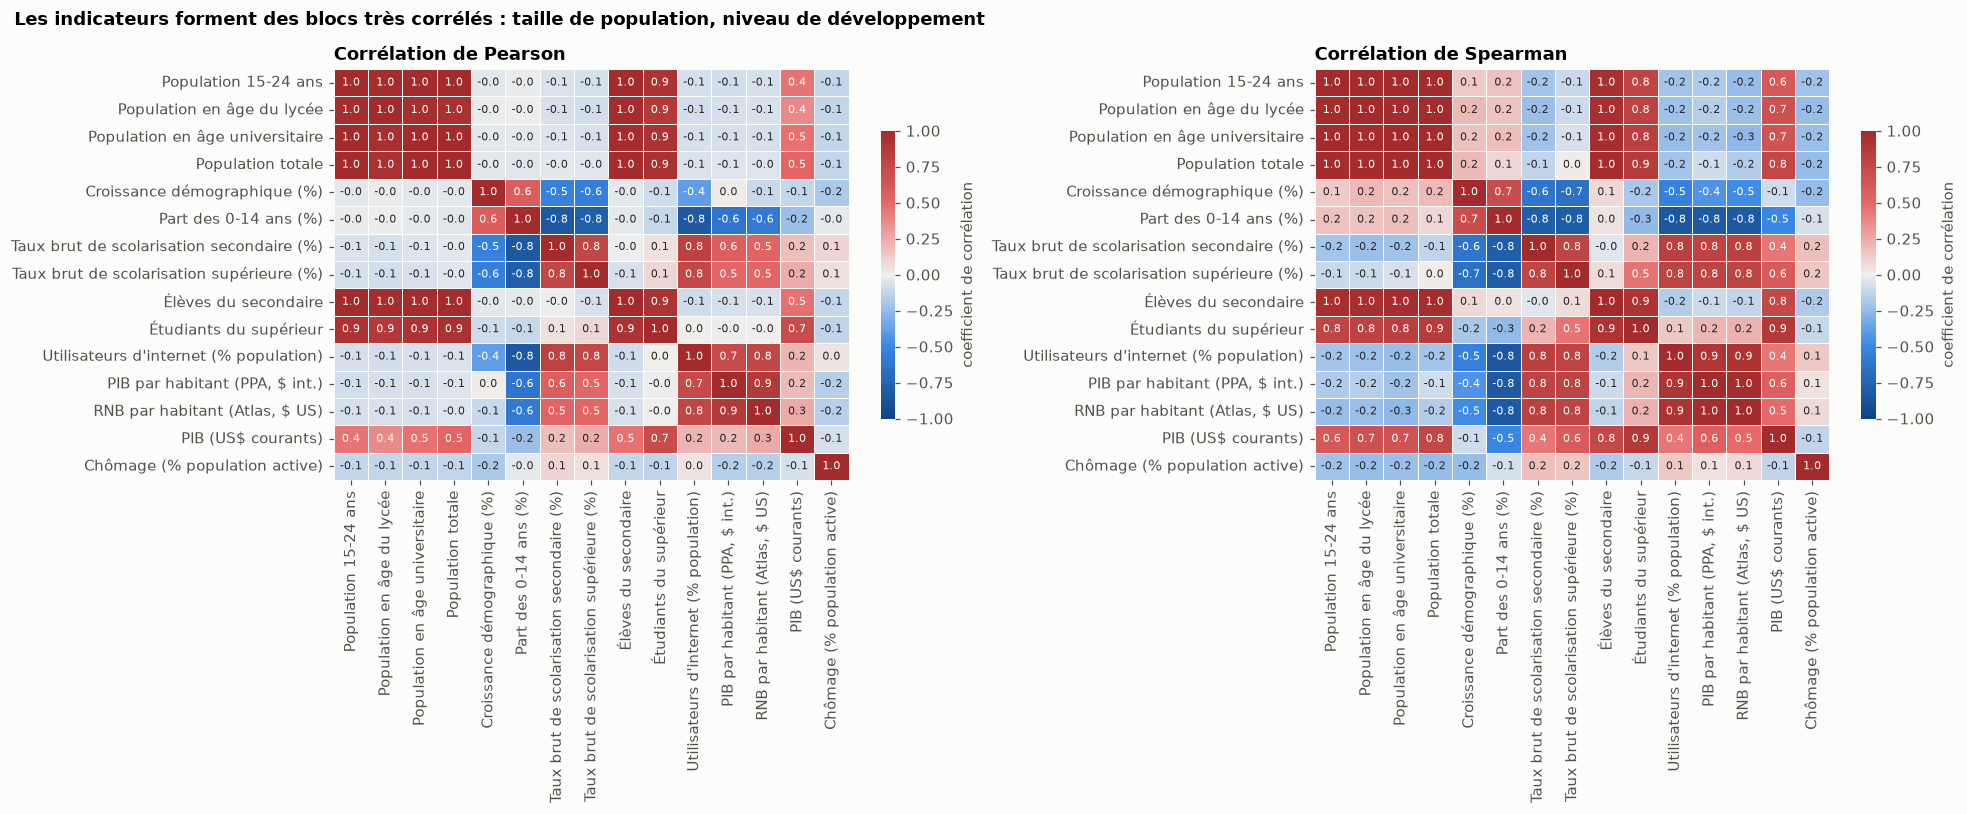

In [31]:
pearson = pays_indicateurs.corr(method="pearson")
spearman = pays_indicateurs.corr(method="spearman")
paires_completes = pays_indicateurs.notna().astype(int).T @ pays_indicateurs.notna().astype(int)
print(f"Nombre de pays par paire : de {paires_completes.values.min()} à {paires_completes.values.max()}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (nom, matrice) in zip(axes, [("Pearson", pearson), ("Spearman", spearman)]):
    sns.heatmap(
        matrice, ax=ax, cmap=viz.DIVERGING, vmin=-1, vmax=1, center=0,
        annot=True, fmt=".1f", annot_kws={"size": 7}, linewidths=0.5, linecolor=viz.SURFACE,
        cbar_kws={"label": "coefficient de corrélation", "shrink": 0.7},
    )
    ax.set_title(f"Corrélation de {nom}")
    ax.set(xlabel="", ylabel="")
fig.suptitle("Les indicateurs forment des blocs très corrélés : taille de population, niveau de développement",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "correlations_pearson_spearman")
plt.show()

In [32]:
paires_redondantes = redundant_pairs(spearman, threshold=SEUIL_CORRELATION)
print(f"{len(paires_redondantes)} paires avec |ρ de Spearman| ≥ {SEUIL_CORRELATION}")
paires_redondantes.round(2).head(20)

34 paires avec |ρ de Spearman| ≥ 0.7


,var_1,var_2,correlation
0,Population 15-24 ans,Population en âge universitaire,1.00
1,Population en âge universitaire,Population totale,0.99
2,Population en âge du lycée,Population en âge universitaire,0.99
3,Population 15-24 ans,Population en âge du lycée,0.99
4,Population 15-24 ans,Population totale,0.99
5,Population en âge du lycée,Population totale,0.98
6,Population totale,Élèves du secondaire,0.98
7,"PIB par habitant (PPA, $ int.)","RNB par habitant (Atlas, $ US)",0.98
8,Population en âge universitaire,Élèves du secondaire,0.97
9,Population 15-24 ans,Élèves du secondaire,0.97


Deux blocs ressortent :
1. **Taille** : population totale, 15-24 ans, âge du lycée, âge universitaire, effectifs scolarisés (ρ > 0,95).
   Ces indicateurs mesurent tous « combien d'habitants » : un seul suffit.
2. **Niveau de développement** : internet, PIB/hab, RNB/hab, taux de scolarisation, part des 0-14 ans (en négatif).
   Les pays riches sont connectés, scolarisés et vieillissants.

Pour départager les indicateurs, on les parcourt **par ordre d'importance pour academy**. Chacun n'est gardé que
s'il n'est pas redondant avec un indicateur déjà retenu.

In [33]:
priorite_metier = [
    "Utilisateurs d'internet (% population)",  # sans internet, pas de client : prérequis absolu
    "Population 15-24 ans",  # le cœur de cible lycée + université
    "Taux brut de scolarisation supérieure (%)",
    "PIB par habitant (PPA, $ int.)",
    "Croissance démographique (%)",
    "Taux brut de scolarisation secondaire (%)",
    "PIB (US$ courants)",
    "Chômage (% population active)",
    "Part des 0-14 ans (%)",
    "Population en âge universitaire",
    "Population en âge du lycée",
    "Population totale",
    "Étudiants du supérieur",
    "Élèves du secondaire",
    "RNB par habitant (Atlas, $ US)",
]
indicateurs_non_redondants = select_non_redundant(spearman, priorite_metier, SEUIL_CORRELATION)
pays_indicateurs_final = pays_indicateurs[indicateurs_non_redondants]
indicateurs_non_redondants

["Utilisateurs d'internet (% population)",
 'Population 15-24 ans',
 'Croissance démographique (%)',
 'PIB (US$ courants)',
 'Chômage (% population active)']

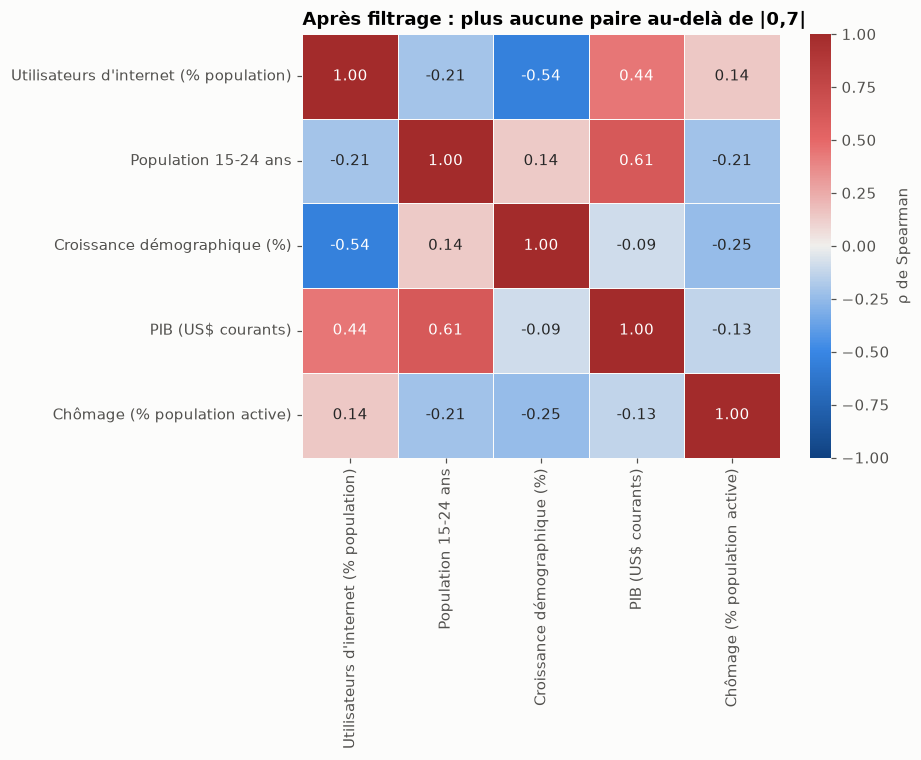

In [34]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    pays_indicateurs_final.corr(method="spearman"), ax=ax, cmap=viz.DIVERGING, vmin=-1, vmax=1,
    annot=True, fmt=".2f", linewidths=0.5, linecolor=viz.SURFACE, cbar_kws={"label": "ρ de Spearman"},
)
ax.set(title="Après filtrage : plus aucune paire au-delà de |0,7|", xlabel="", ylabel="")
viz.save(fig, "correlations_apres_filtrage")
plt.show()

**Ce que la corrélation ne dit pas.** Le taux d'internet « représente » désormais tout le bloc développement :
il est corrélé à 0,9 au PIB/hab (PPA) et à 0,8 au taux de scolarisation supérieure. Ce n'est pas une causalité
(internet ne *fait* pas aller à l'université), c'est un **résumé** : savoir l'un renseigne beaucoup sur l'autre.

### 3.2 Distributions des indicateurs retenus

D'abord un indicateur, pour mettre au point la méthode…

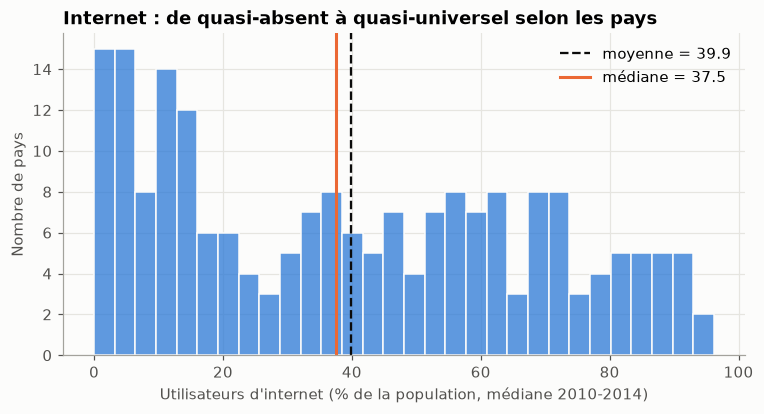

count        203.0
mean          39.9
std           28.5
min            0.0
25%           12.5
50%           37.5
75%           62.1
max           96.2
asymetrie      0.2
Name: Utilisateurs d'internet (% population), dtype: float64

In [35]:
stats_internet = describe_and_plot(
    pays_indicateurs_final["Utilisateurs d'internet (% population)"],
    title="Internet : de quasi-absent à quasi-universel selon les pays",
    xlabel="Utilisateurs d'internet (% de la population, médiane 2010-2014)",
    save_as="distribution_internet",
)
stats_internet.round(1)

…puis la même fonction appliquée à tous les indicateurs dans une boucle. Les indicateurs de **taille**
(population, PIB) couvrent plusieurs ordres de grandeur : on les trace en **échelle logarithmique**, sans quoi tous
les pays seraient écrasés dans la première barre.

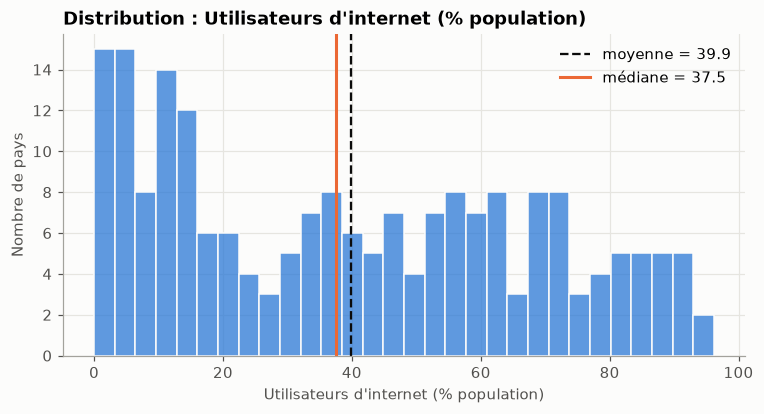

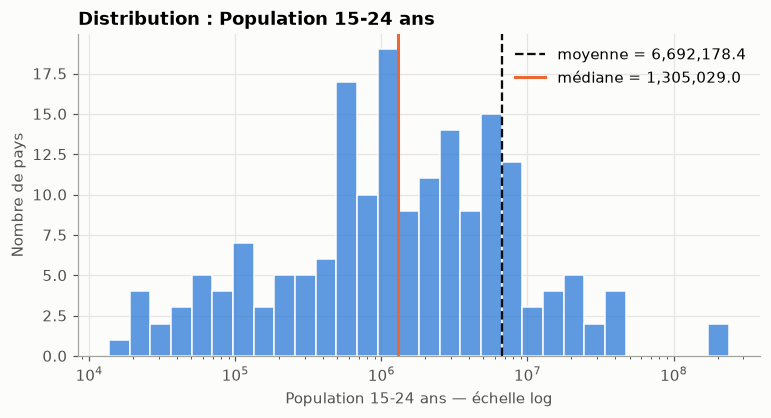

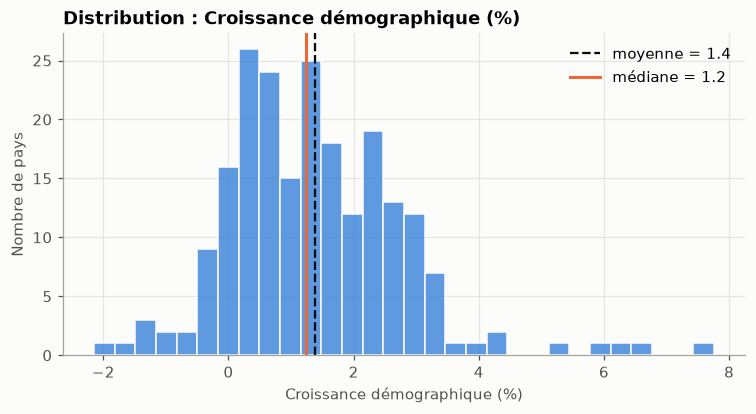

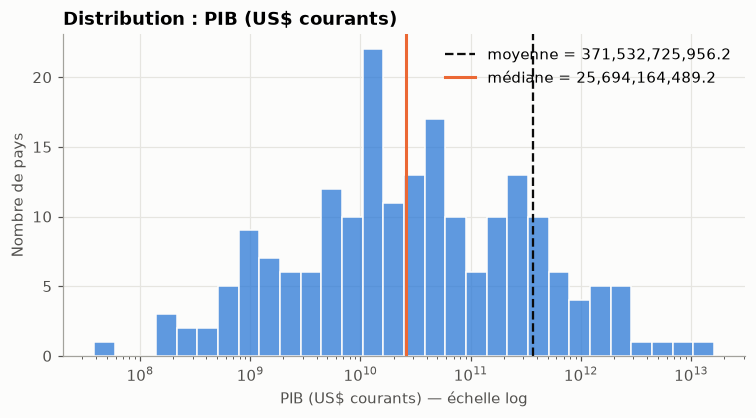

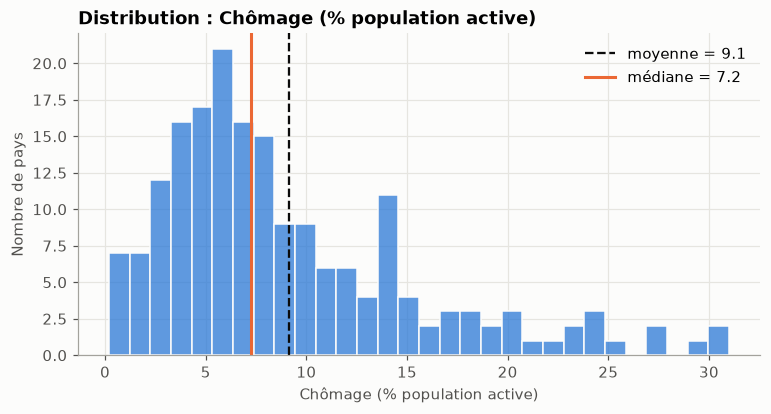

,Utilisateurs d'internet (% population),Population 15-24 ans,Croissance démographique (%),PIB (US$ courants),Chômage (% population active)
count,203.00,1.810000e+02,214.00,1.990000e+02,186.00
mean,39.88,6.692178e+06,1.38,3.715327e+11,9.12
std,28.51,2.445723e+07,1.40,1.428972e+12,6.53
min,0.00,1.370800e+04,-2.15,3.832236e+07,0.20
25%,12.54,5.102590e+05,0.45,6.244054e+09,4.50
50%,37.50,1.305029e+06,1.24,2.569416e+10,7.25
75%,62.13,4.938116e+06,2.22,2.002337e+11,12.15
max,96.21,2.397136e+08,7.76,1.615526e+13,31.00
asymetrie,0.25,8.240000e+00,1.00,8.250000e+00,1.29


In [36]:
echelle_log = {"Population 15-24 ans", "PIB (US$ courants)"}
statistiques = {}
for indicateur in indicateurs_non_redondants:
    statistiques[indicateur] = describe_and_plot(
        pays_indicateurs_final[indicateur],
        title=f"Distribution : {indicateur}",
        xlabel=indicateur + (" — échelle log" if indicateur in echelle_log else ""),
        log_scale=indicateur in echelle_log,
    )
pd.DataFrame(statistiques).round(2)

**Interprétation des distributions** (une ligne = un pays ; médiane 2010-2014)

| Indicateur | Ce que dit `describe()` | Lecture métier |
|---|---|---|
| Internet (% population) | moyenne 40 ≈ médiane 37,5, asymétrie 0,25 : distribution **étalée et presque symétrique**, de 0 à 96 % | pas de « pays type » : un quart des pays a moins de 12,5 % d'internautes, un autre quart plus de 62 %. Le critère discrimine bien les pays |
| Population 15-24 ans | moyenne 6,7 M ≫ médiane 1,3 M, max 240 M (Inde), asymétrie 8 | **très asymétrique** : quelques géants (Inde, Chine) et une majorité de petits pays. La moyenne ne représente personne, il faut raisonner en médiane ou en échelle log |
| Croissance démographique (%) | médiane 1,2 %, Q1 0,45 %, Q3 2,2 %, min négatif | la plupart des populations croissent ; une poignée décroît : Syrie (guerre), pays baltes, Géorgie, Bosnie, Bulgarie |
| PIB (US$ courants) | moyenne 372 Md ≫ médiane 26 Md, asymétrie 8 | même structure que la population : les États-Unis et la Chine écrasent la distribution |
| Chômage (%) | médiane 7,3 %, Q3 12 %, max 31 % | queue à droite : Balkans (Macédoine, Bosnie), Afrique australe (Eswatini, Lesotho, Afrique du Sud), et l'Espagne à 24 % après la crise de 2008 |

**Comment repérer des valeurs extrêmes avec `describe()`** : comparer la moyenne et la médiane (un écart important
signale une asymétrie), puis l'écart entre le max et Q3 avec l'écart entre Q3 et la médiane. Pour la population
15-24 ans, max − Q3 ≈ 235 M alors que Q3 − médiane ≈ 3,6 M : la queue droite est extrême.

### 3.3 Comment le potentiel va-t-il évoluer ? (projections 2015 → 2030)

Les projections Wittgenstein donnent, par pays, la population de 15-19 et 20-24 ans selon le niveau d'études.
Notre cible : les jeunes de **15-24 ans ayant au moins le niveau lycée** (secondaire supérieur ou post-secondaire).
On calcule son évolution entre 2015 et 2030.

In [37]:
codes_cible = [f"PRJ.POP.{age}.{niveau}.MF" for age in ("1519", "2024") for niveau in ("3", "4")]
cible = projections[projections["Indicator Code"].isin(codes_cible)]
cible_par_pays = cible.groupby("Country Code")[[ANNEE_REFERENCE, ANNEE_PROJECTION]].sum(min_count=len(codes_cible))
croissance_cible = (cible_par_pays[ANNEE_PROJECTION] / cible_par_pays[ANNEE_REFERENCE] - 1).rename(
    "Croissance projetée des 15-24 ans diplômés du lycée (2015-2030)"
)
print(f"{croissance_cible.notna().sum()} pays avec une projection")
croissance_cible.describe().round(2)

166 pays avec une projection


count    166.00
mean       0.37
std        0.48
min       -0.29
25%        0.02
50%        0.24
75%        0.55
max        1.85
Name: Croissance projetée des 15-24 ans diplômés du lycée (2015-2030), dtype: float64

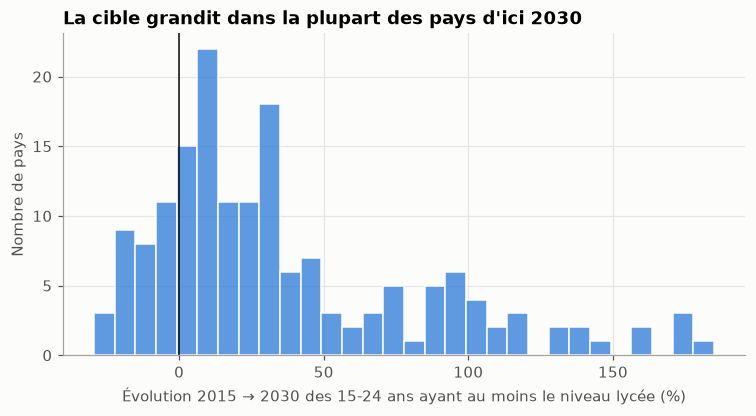

In [38]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(croissance_cible * 100, bins=30, color=viz.BLUE, edgecolor=viz.SURFACE, ax=ax)
ax.axvline(0, color=viz.TEXT, linewidth=1)
ax.set(
    title="La cible grandit dans la plupart des pays d'ici 2030",
    xlabel="Évolution 2015 → 2030 des 15-24 ans ayant au moins le niveau lycée (%)",
    ylabel="Nombre de pays",
)
viz.save(fig, "croissance_cible_2030")
plt.show()

### 3.4 Sélectionner des pays : une méthode quantitative

On construit 3 critères **peu corrélés** à partir des indicateurs retenus :

| Critère | Calcul | Ce qu'il mesure pour academy |
|---|---|---|
| Marché connecté | population 15-24 ans × % d'internautes | combien de clients potentiels peuvent suivre un cours en ligne |
| Maturité numérique | % d'internautes | usage du numérique, et indirectement pouvoir d'achat (ρ ≈ 0,9 avec le PIB/hab) |
| Dynamique | croissance projetée de la cible 2015-2030 | le marché de demain |

Pour éviter qu'un critère en milliards écrase un critère en pourcentage, chaque critère est converti en **rang
percentile** (0 = dernier pays, 1 = premier), puis on fait une **moyenne pondérée**.

In [39]:
criteres = pd.DataFrame(
    {
        "marche_connecte": pays_indicateurs_final["Population 15-24 ans"]
        * pays_indicateurs_final["Utilisateurs d'internet (% population)"] / 100,
        "maturite_numerique": pays_indicateurs_final["Utilisateurs d'internet (% population)"],
        "dynamique": croissance_cible,
    }
)
print(f"{len(criteres)} pays, dont {criteres.notna().all(axis=1).sum()} avec les 3 critères")
criteres_complets = criteres.dropna()
criteres_complets.corr(method="spearman").round(2)

216 pays, dont 161 avec les 3 critères


,marche_connecte,maturite_numerique,dynamique
marche_connecte,1.00,0.38,-0.26
maturite_numerique,0.38,1.00,-0.66
dynamique,-0.26,-0.66,1.00


In [40]:
pays_sans_score = criteres[criteres.isna().any(axis=1)].join(country.set_index("Country Code")["Short Name"])
pays_sans_score.sort_values("marche_connecte", ascending=False).head(8)

,marche_connecte,maturite_numerique,dynamique,Short Name
Country Code,,,,
UZB,1.463374e+06,23.600000,NaN,Uzbekistan
YEM,9.830848e+05,17.446500,NaN,Yemen
LKA,5.748599e+05,18.285400,NaN,Sri Lanka
AFG,3.583221e+05,5.454545,NaN,Afghanistan
OMN,3.468924e+05,60.000000,NaN,Oman
AGO,2.582158e+05,6.500000,NaN,Angola
LBY,1.701441e+05,15.250000,NaN,Libya
BWA,6.989712e+04,16.000000,NaN,Botswana


⚠️ 55 pays sortent du score faute de projection ou de données d'internet. On **regarde** ce que `dropna()` supprime
au lieu de lui faire confiance : aucun des très grands marchés (Chine, Inde, États-Unis, Brésil, Nigeria) n'est perdu.
Les plus gros absents sont l'Ouzbékistan, le Yémen et le Sri Lanka : à signaler à Mark comme angle mort.

**Méthode A : moyenne pondérée des rangs.** Poids fixés *a priori* par le métier : la taille du marché accessible
d'abord (50 %), la maturité ensuite (30 %), la dynamique enfin (20 %).

In [41]:
POIDS = {"marche_connecte": 0.5, "maturite_numerique": 0.3, "dynamique": 0.2}
noms_pays = country.set_index("Country Code")["Short Name"]

score = percentile_score(criteres_complets, POIDS).rename("score")
classement = (
    criteres_complets.join(score).join(noms_pays).sort_values("score", ascending=False)
    .assign(rang=lambda d: range(1, len(d) + 1))
)
classement.head(15).style.format(
    {"marche_connecte": "{:,.0f}", "maturite_numerique": "{:.0f} %", "dynamique": "{:+.0%}", "score": "{:.2f}"}
)

,marche_connecte,maturite_numerique,dynamique,score,Short Name,rang
Country Code,,,,,,
GBR,"6,959,078",87 %,+21%,0.85,United Kingdom,1
FRA,"6,170,693",81 %,+20%,0.82,France,2
USA,"32,472,803",72 %,+8%,0.80,United States,3
RUS,"11,330,801",64 %,+14%,0.80,Russia,4
ESP,"3,088,725",70 %,+32%,0.78,Spain,5
DEU,"7,503,384",82 %,-7%,0.78,Germany,6
JPN,"9,821,799",79 %,-6%,0.78,Japan,7
MAR,"3,477,956",55 %,+42%,0.77,Morocco,8
MEX,"8,020,714",40 %,+31%,0.76,Mexico,9


**Méthode B : intersection des tops** (suggérée par l'énoncé). On prend le top 20 de chaque critère et on compte
dans combien de tops chaque pays apparaît.

In [42]:
TOP_N = 20
presence_dans_les_tops = sum(
    criteres_complets[c].rank(ascending=False).le(TOP_N).astype(int) for c in criteres_complets.columns
)
presence = presence_dans_les_tops[presence_dans_les_tops >= 2].sort_values(ascending=False)
presence.to_frame("nb de tops").join(noms_pays)

,nb de tops,Short Name
Country Code,,
DEU,2,Germany
FRA,2,France
GBR,2,United Kingdom
JPN,2,Japan
KOR,2,Korea


La dynamique est **anti-corrélée** à la maturité (ρ ≈ -0,7) : les pays dont la cible grandit le plus sont ceux qui
sont aujourd'hui les moins connectés. Très peu de pays sont dans les trois tops à la fois. Ce n'est pas un défaut de
la méthode : c'est **l'information principale** pour Mark. Il y a deux types de marchés, et donc deux stratégies.

**Robustesse.** Nos poids sont un choix. Que se passe-t-il si on en tire 1 000 au hasard ?

In [43]:
frequence_top10 = weight_sensitivity(criteres_complets, list(POIDS), n_draws=1000, top=10, seed=42)
robustesse = frequence_top10.to_frame().join(noms_pays).join(classement["rang"]).head(15)
robustesse.style.format({"frequence_top": "{:.0%}"})

,frequence_top,Short Name,rang
Country Code,,,
GBR,74%,United Kingdom,1
FRA,59%,France,2
ARE,42%,United Arab Emirates,22
SAU,42%,Saudi Arabia,10
MAR,42%,Morocco,8
ESP,41%,Spain,5
NGA,39%,Nigeria,21
ISR,38%,Israel,20
USA,37%,United States,3


Lecture : un pays présent dans le top 10 dans plus de 50 % des tirages reste bien classé **quels que soient les
poids**. C'est une recommandation solide. Un pays du top 10 « officiel » qui n'apparaît que dans 20 % des tirages
dépend surtout de nos poids : il faut le présenter comme tel.

### 3.5 Synthèse visuelle : deux familles de marchés

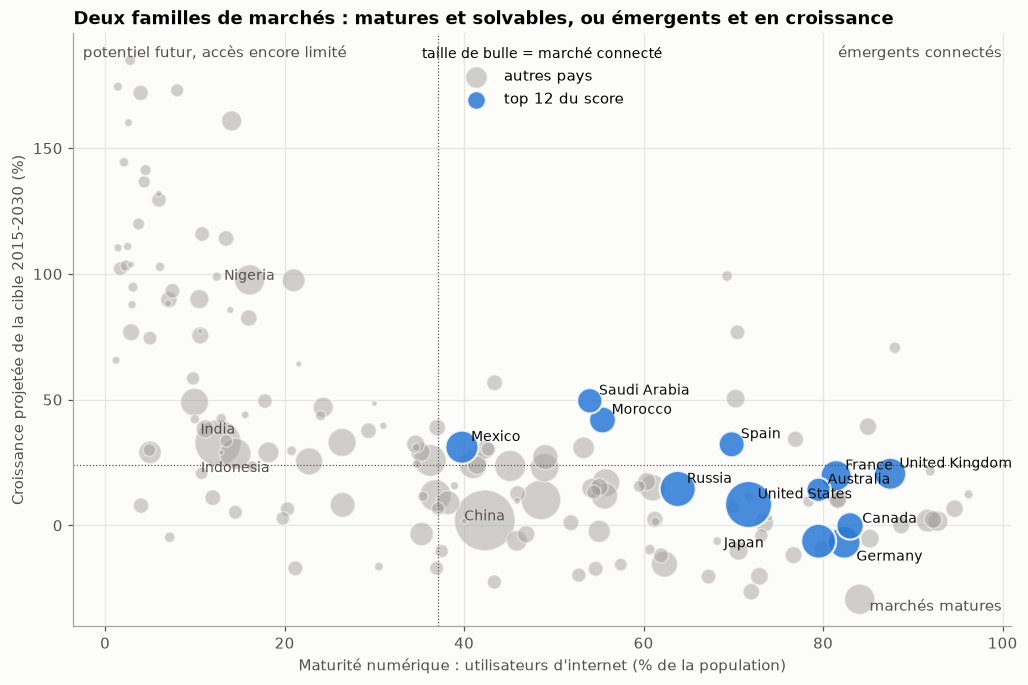

In [44]:
carte = classement.copy()
seuil_maturite = carte["maturite_numerique"].median()
seuil_dynamique = carte["dynamique"].median()
top = carte.head(12).index

fig, ax = plt.subplots(figsize=(11, 7))
autres = carte.drop(index=top)
ax.scatter(autres["maturite_numerique"], autres["dynamique"] * 100,
           s=np.sqrt(autres["marche_connecte"]) / 6, color=viz.MUTED, alpha=0.5,
           edgecolor=viz.SURFACE, linewidth=1, label="autres pays")
ax.scatter(carte.loc[top, "maturite_numerique"], carte.loc[top, "dynamique"] * 100,
           s=np.sqrt(carte.loc[top, "marche_connecte"]) / 6, color=viz.BLUE, alpha=0.85,
           edgecolor=viz.SURFACE, linewidth=1.5, label="top 12 du score")
decalages = {"DEU": (8, -12), "JPN": (-62, -4), "CAN": (8, 2)}
for code_pays in top:
    ax.annotate(carte.loc[code_pays, "Short Name"],
                (carte.loc[code_pays, "maturite_numerique"], carte.loc[code_pays, "dynamique"] * 100),
                xytext=decalages.get(code_pays, (6, 4)), textcoords="offset points", fontsize=9, color=viz.TEXT)
for code_pays, decalage in {"CHN": (0, 0), "IND": (0, 6), "NGA": (0, 0), "IDN": (0, -12)}.items():
    # grands marchés hors top : Mark posera la question
    ax.annotate(carte.loc[code_pays, "Short Name"],
                (carte.loc[code_pays, "maturite_numerique"], carte.loc[code_pays, "dynamique"] * 100),
                xytext=decalage, textcoords="offset points", fontsize=9, color=viz.TEXT_2, ha="center")
ax.axvline(seuil_maturite, color=viz.TEXT_2, linewidth=0.8, linestyle=":")
ax.axhline(seuil_dynamique * 100, color=viz.TEXT_2, linewidth=0.8, linestyle=":")
ax.text(0.99, 0.98, "émergents connectés", transform=ax.transAxes, ha="right", va="top", color=viz.TEXT_2)
ax.text(0.99, 0.02, "marchés matures", transform=ax.transAxes, ha="right", va="bottom", color=viz.TEXT_2)
ax.text(0.01, 0.98, "potentiel futur, accès encore limité", transform=ax.transAxes, ha="left", va="top", color=viz.TEXT_2)
ax.set(
    title="Deux familles de marchés : matures et solvables, ou émergents et en croissance",
    xlabel="Maturité numérique : utilisateurs d'internet (% de la population)",
    ylabel="Croissance projetée de la cible 2015-2030 (%)",
)
ax.legend(loc="upper center", markerscale=0.5, title="taille de bulle = marché connecté", title_fontsize=9)
viz.save(fig, "carte_marches")
plt.show()

In [45]:
def famille_de_marche(ligne):
    mature = ligne["maturite_numerique"] >= seuil_maturite
    dynamique = ligne["dynamique"] >= seuil_dynamique
    if mature and dynamique:
        return "émergent connecté"
    if mature:
        return "mature"
    if dynamique:
        return "potentiel futur"
    return "faible priorité"


classement["famille"] = classement.apply(famille_de_marche, axis=1)
recommandation = classement.head(15)[["Short Name", "famille", "score", "rang"]].join(frequence_top10)
recommandation.style.format({"score": "{:.2f}", "frequence_top": "{:.0%}"})

,Short Name,famille,score,rang,frequence_top
Country Code,,,,,
GBR,United Kingdom,mature,0.85,1,74%
FRA,France,mature,0.82,2,59%
USA,United States,mature,0.80,3,37%
RUS,Russia,mature,0.80,4,34%
ESP,Spain,émergent connecté,0.78,5,41%
DEU,Germany,mature,0.78,6,30%
JPN,Japan,mature,0.78,7,27%
MAR,Morocco,émergent connecté,0.77,8,42%
MEX,Mexico,émergent connecté,0.76,9,30%


### 3.6 Réponse à Mark

**1. EdStats permet-il d'éclairer l'expansion ? Oui, pour un premier tri, mais pas seul.**
- ✅ Il couvre 216 pays avec des indicateurs harmonisés sur les 4 dimensions utiles : démographie, scolarisation,
  accès à internet, économie. Il contient en plus des projections jusqu'en 2100.
- ⚠️ Les données exploitables s'arrêtent en **2014** et sont très lacunaires (86 % de cellules vides dans `Data`) :
  le taux d'internet a fortement progressé depuis.
- ❌ Il ne dit rien de la **langue**, de la **concurrence**, du **prix acceptable** ni de la **réglementation** :
  ces critères décisifs pour academy devront venir d'autres sources.

**2. Où s'implanter ? Il existe deux stratégies, que les données séparent nettement.**

| Famille | Pays | Argument | Risque |
|---|---|---|---|
| **Marchés matures** : priorité 1 | Royaume-Uni, France, États-Unis, Allemagne, Japon | gros marché connecté, solvable | cible stable ou en baisse d'ici 2030, concurrence forte |
| **Émergents connectés** : priorité 2 | Maroc, Arabie saoudite, Espagne, Mexique, Émirats | déjà connectés **et** cible en forte croissance | pouvoir d'achat plus hétérogène |
| **Potentiel futur** : veille | Nigeria, Inde, Égypte | cible en très forte croissance | accès à internet encore limité en 2014 |

**3. Robustesse.** Seuls le **Royaume-Uni** et la **France** restent dans le top 10 pour la majorité des jeux de
poids. Pour les autres pays, le classement dépend de l'arbitrage stratégique entre maturité et croissance : c'est à
Mark de le trancher, pas aux données.

**Prochaines étapes proposées** : actualiser les données avec l'API de la Banque mondiale et les données de l'UIT
pour internet, ajouter la langue d'enseignement et le prix moyen de l'EdTech locale, puis valider par une étude de
marché sur 2 ou 3 pays pilotes.

> Ces résultats décrivent des **associations** entre indicateurs, pas des causes : un pays connecté n'est pas
> « rendu » rentable par internet. Le score est un **outil de tri**, pas une prévision de chiffre d'affaires.

In [46]:
from pathlib import Path

sortie = Path("../data/processed")
sortie.mkdir(parents=True, exist_ok=True)
pays_indicateurs.join(noms_pays).to_csv(sortie / "pays_indicateurs.csv")
classement.join(frequence_top10).to_csv(sortie / "classement_pays.csv")
journal.to_frame().to_csv(sortie / "journal_nettoyage.csv", index=False)
print("Exports :", sorted(p.name for p in sortie.iterdir()))

Exports : ['classement_pays.csv', 'journal_nettoyage.csv', 'pays_indicateurs.csv']


---
## Livrable 3 — Reproduire l'environnement

```bash
uv sync --frozen          # installe exactement les versions de uv.lock
uv run jupyter lab        # ouvre ce notebook dans l'environnement du projet
```

`pyproject.toml` liste les dépendances, et `uv.lock` fige leurs versions exactes ainsi que celles de leurs
propres dépendances : un collègue obtient le même environnement, donc les mêmes résultats.